## Revisão de Aprendizado de Máquina e Exemplo de Descida de Gradiente

Neste notebook, resolveremos um problema simples de regressão linear usando descida de gradiente.  
Veremos o efeito da taxa de aprendizagem na trajetória no espaço de parâmetros.
Mostraremos como a Descida de Gradiente Estocástica (SGD) difere da versão padrão, e o efeito de "embaralhar" seus dados durante o SGD.

In [218]:
import sys
sys.version

'3.12.3 (main, Apr 30 2026, 22:51:13) [GCC 13.3.0]'

In [219]:
# Preparação inicial - pacotes a serem carregados

from __future__ import print_function
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

## Gerar Dados de uma Distribuição Conhecida
Abaixo geraremos dados de uma distribuição conhecida.  
Especificamente, o modelo verdadeiro é:

$Y = b + \theta_1 X_1 + \theta_2 X_2 + \epsilon$

$X_1$ e $X_2$ têm uma distribuição uniforme no intervalo $[0,10]$, enquanto `const` é um vetor de uns (representando o termo de intercepto).

Definimos valores reais para $b$, $\theta_1$, e $\theta_2$

Aqui $b=1.5$, $\theta_1=2$, e $\theta_2=5$

Em seguida, geramos um vetor de valores de $y$ de acordo com o modelo e juntamos os preditores em uma "matriz de características" `x_mat`

In [220]:
np.random.seed(1234)  ## Isso garante que obtemos os mesmos dados se todos os outros parâmetros permanecerem fixos

num_obs = 100
x1 = np.random.uniform(0,10,num_obs)
x2 = np.random.uniform(0,10,num_obs)
const = np.ones(num_obs)
eps = np.random.normal(0,.5,num_obs)

b = 1.5
theta_1 = 2
theta_2 = 5

y = b*const + theta_1*x1 + theta_2*x2 + eps

x_mat = np.array([const,x1,x2]).T

display(x_mat)

array([[1.        , 1.9151945 , 7.67116628],
       [1.        , 6.22108771, 7.08115362],
       [1.        , 4.37727739, 7.96867184],
       [1.        , 7.85358584, 5.57760828],
       [1.        , 7.79975808, 9.65836532],
       [1.        , 2.72592605, 1.471569  ],
       [1.        , 2.76464255, 0.29647001],
       [1.        , 8.01872178, 5.93893493],
       [1.        , 9.58139354, 1.14065699],
       [1.        , 8.75932635, 9.5080985 ],
       [1.        , 3.5781727 , 3.25707414],
       [1.        , 5.00995126, 1.9361869 ],
       [1.        , 6.83462935, 4.57811649],
       [1.        , 7.12702027, 9.20402571],
       [1.        , 3.70250755, 8.79069162],
       [1.        , 5.61196186, 2.52615755],
       [1.        , 5.03083165, 3.48008793],
       [1.        , 0.1376845 , 1.82588732],
       [1.        , 7.72826622, 9.01796051],
       [1.        , 8.82641191, 7.06528163],
       [1.        , 3.64885984, 7.26658462],
       [1.        , 6.15396178, 9.00087837],
       [1.

## Obter a Resposta "Correta" Diretamente
Nas células abaixo, resolvemos para o conjunto ótimo de coeficientes. Note que, embora o modelo verdadeiro seja dado por:

$b=1.5$, $\theta_1=2$, e $\theta_2=5$

A estimativa de máxima verossimilhança (mínimos quadrados) de um conjunto de dados finito pode ser ligeiramente diferente.

## Exercício:
Resolva o problema de duas maneiras: 
1. Usando o modelo LinearRegression do scikit-learn
2. Usando álgebra matricial diretamente através da fórmula $\theta = (X^T X)^{-1}X^Ty$

Nota: O solver do scikit-learn pode mostrar uma mensagem de aviso, isso pode ser ignorado.

In [221]:
### Resolver diretamente usando sklearn
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression(fit_intercept=False)
lr_model.fit(x_mat, y)

lr_model.coef_

array([1.49004618, 1.99675416, 5.01156315])

In [222]:
## Resolver por cálculo matricial
np.linalg.inv(np.dot(x_mat.T,x_mat)).dot(x_mat.T).dot(y)

array([1.49004618, 1.99675416, 5.01156315])

## Resolvendo por Descida de Gradiente
Outra maneira de resolver este problema é usar o método de Descida de Gradiente. Exploraremos este método porque (como veremos) as Redes Neurais são treinadas por Descida de Gradiente. Ver como a descida de gradiente funciona em um exemplo simples construirá intuição e nos ajudará a entender algumas das nuances sobre definir a taxa de aprendizagem. Também exploraremos a Descida de Gradiente Estocástica e compararemos seu comportamento com a abordagem padrão.

## Exercício

As próximas várias células contêm código para executar descida de gradiente (full-batch). Omitimos alguns parâmetros para você preencher.

1. Escolha uma taxa de aprendizagem e um número de iterações, execute o código e então plote a trajetória de sua descida de gradiente.
1. Encontre exemplos onde a taxa de aprendizagem é muito alta, muito baixa e "perfeita".
1. Observe os gráficos da função de perda sob essas condições.



In [231]:
## Parâmetros para experimentar
learning_rate = .0001
num_iter = 10000
theta_initial = np.array([5,0.1,1])

display(theta_initial)

array([5. , 0.1, 1. ])

In [232]:
## Passos de inicialização
theta = theta_initial
theta_path = np.zeros((num_iter+1,3))
theta_path[0,:]= theta_initial

loss_vec = np.zeros(num_iter)

## Loop principal da Descida de Gradiente (para um número fixo de iterações)
for i in range(num_iter):
    y_pred = np.dot(theta.T,x_mat.T)
    loss_vec[i] = np.sum((y-y_pred)**2)
    grad_vec = (y-y_pred).dot(x_mat)/num_obs  #soma os gradientes de todas as observações e divide por num_obs
    grad_vec = grad_vec
    theta = theta + learning_rate*grad_vec
    theta_path[i+1,:]=theta
    

(0.0, 500.0)

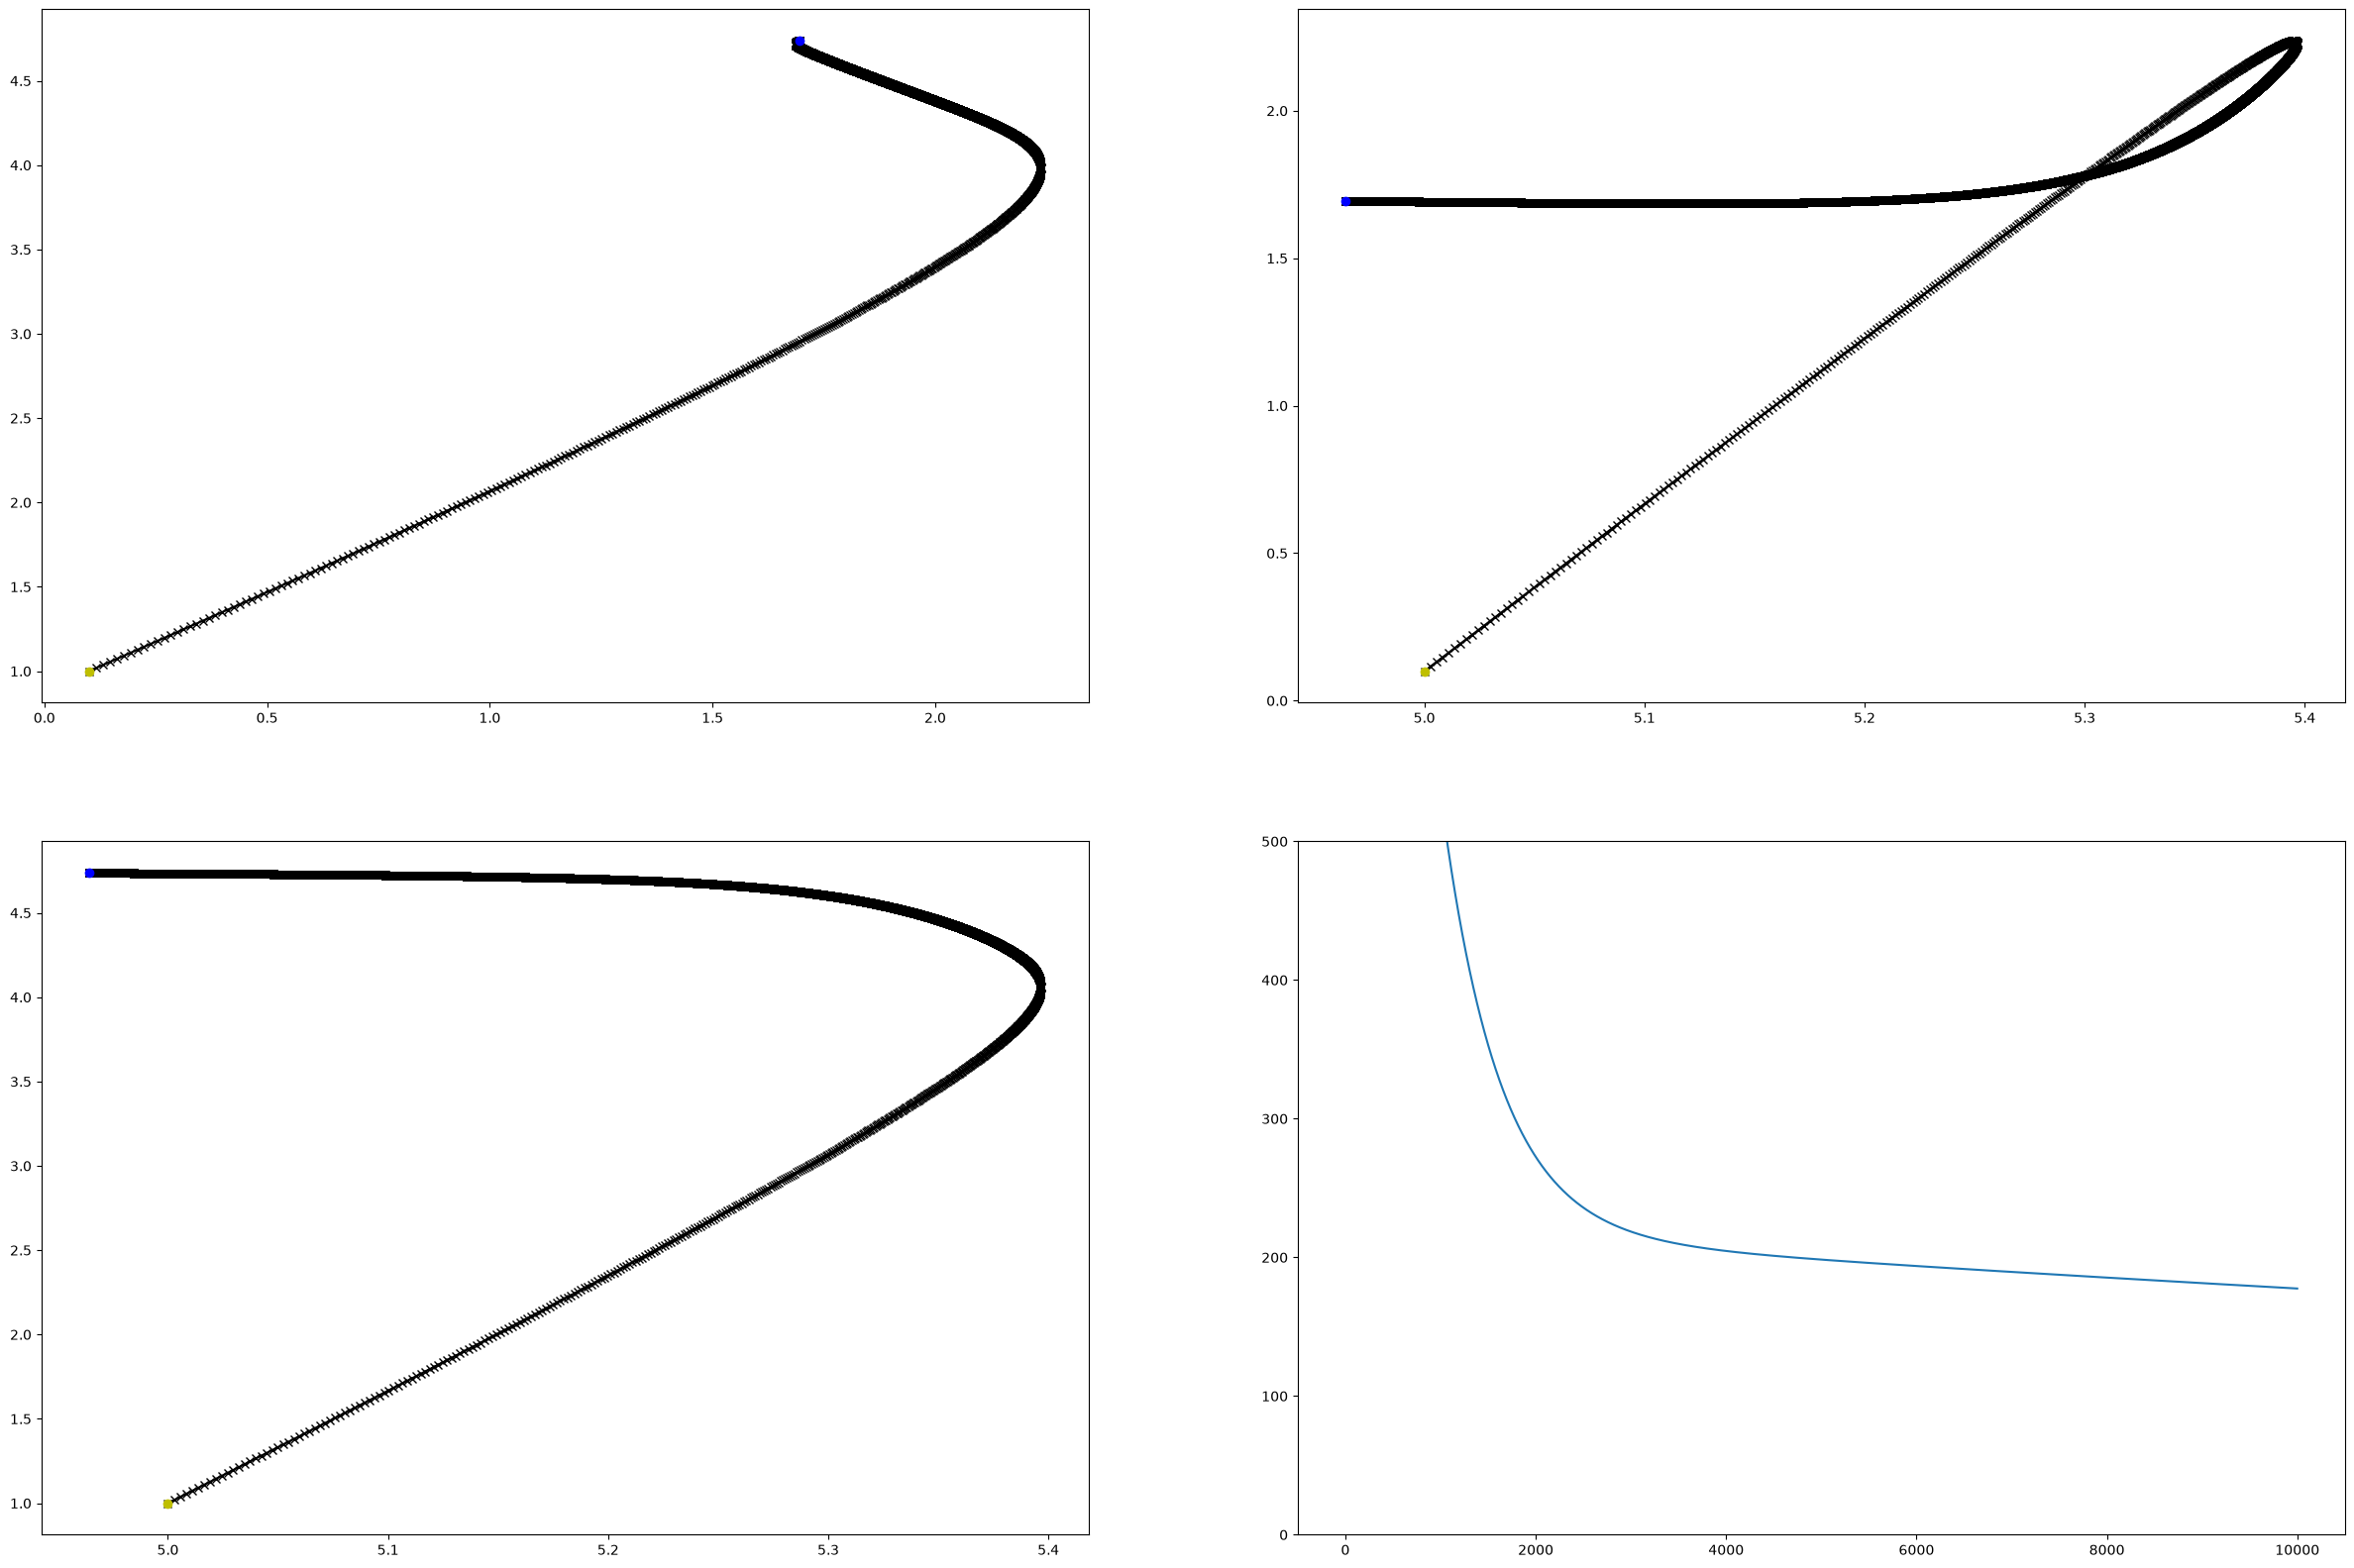

In [233]:
    
## Plotar os resultados - é um espaço de parâmetros 3d - plotamos fatias 2d
## Amarelo é ponto inicial e azul é ponto final
plt.figure(figsize = (30,20))
plt.subplot(2,2,1)
plt.plot(theta_path[:,1],theta_path[:,2],'k-x')
plt.plot(theta_path[0,1],theta_path[0,2],'yo')
plt.plot(theta_path[-1,1],theta_path[-1,2],'bo')
plt.subplot(2,2,2)
plt.plot(theta_path[:,0],theta_path[:,1],'k-x')
plt.plot(theta_path[0,0],theta_path[0,1],'yo')
plt.plot(theta_path[-1,0],theta_path[-1,1],'bo')

plt.subplot(2,2,3)
plt.plot(theta_path[:,0],theta_path[:,2],'k-x')
plt.plot(theta_path[0,0],theta_path[0,2],'yo')
plt.plot(theta_path[-1,0],theta_path[-1,2],'bo')

plt.subplot(2,2,4)
plt.plot(loss_vec)
plt.ylim([0,500])

## Plotar a função de perda

1- experimental
2- 

aprendizado baixo:
(não se aproxima dos valores esperados, visível pelo gráfico, causado pela distancia dos parametros originais e pelo learning_rate pequeno, que não permite grande mudança)

learning_rate = .0001
num_iter = 100000
theta_initial = np.array([5,0.1,1])

aprendizado "perfeito":
(corrije a diferença rapidamente e vai "refinando", acredito que o learning_rate alto, a quantidade suficiente de iterações e a proximidade dos parametros iniciais facilitam esse aprendizado)

learning_rate = .0015
num_iter = 10000
theta_initial = np.array([4,4,4])

aprendizado alto:

(aprendizado alto visível na curva que o mse faz, além da distância dos parâmetros inciais para os encontrados e o learning_rate alto)

learning_rate = .005
num_iter = 10000
theta_initial = np.array([7,7,7])


3- experimental

## Descida de Gradiente Estocástica
Em vez de calcular a média dos gradientes em todo o conjunto de dados antes de dar um passo, agora daremos um passo para cada ponto de dados. Cada passo será uma "reação excessiva", mas eles devem se equilibrar.

## Exercício
O código abaixo executa a Descida de Gradiente Estocástica, mas percorre os dados na mesma ordem a cada vez.  

1. Execute o código e plote os gráficos. O que você observa?
2. Modifique o código para que ele reordene os dados aleatoriamente. Como as trajetórias das amostras se comparam? _VOCÊ DEVE COMPLETAR AQUI_

In [226]:
## Parâmetros para experimentar
learning_rate = .002
num_iter = 10 #O número de "passos" será num_iter * numobs
theta_initial = np.array([3,3,3])

In [227]:
## Passos de inicialização
theta = theta_initial
theta_path = np.zeros(((num_iter*num_obs)+1,3))
theta_path[0,:]= theta_initial
loss_vec = np.zeros(num_iter*num_obs)

In [228]:
## Loop principal do SGD
count = 0
for i in range(num_iter):
    for j in range(num_obs):
        count+=1
        y_pred = np.dot(theta.T,x_mat.T)
        loss_vec[count-1] = np.sum((y-y_pred)**2)
        grad_vec = (y[j]-y_pred[j])*(x_mat[j,:])
        theta = theta + learning_rate*grad_vec
        theta_path[count,:]=theta

(0.0, 500.0)

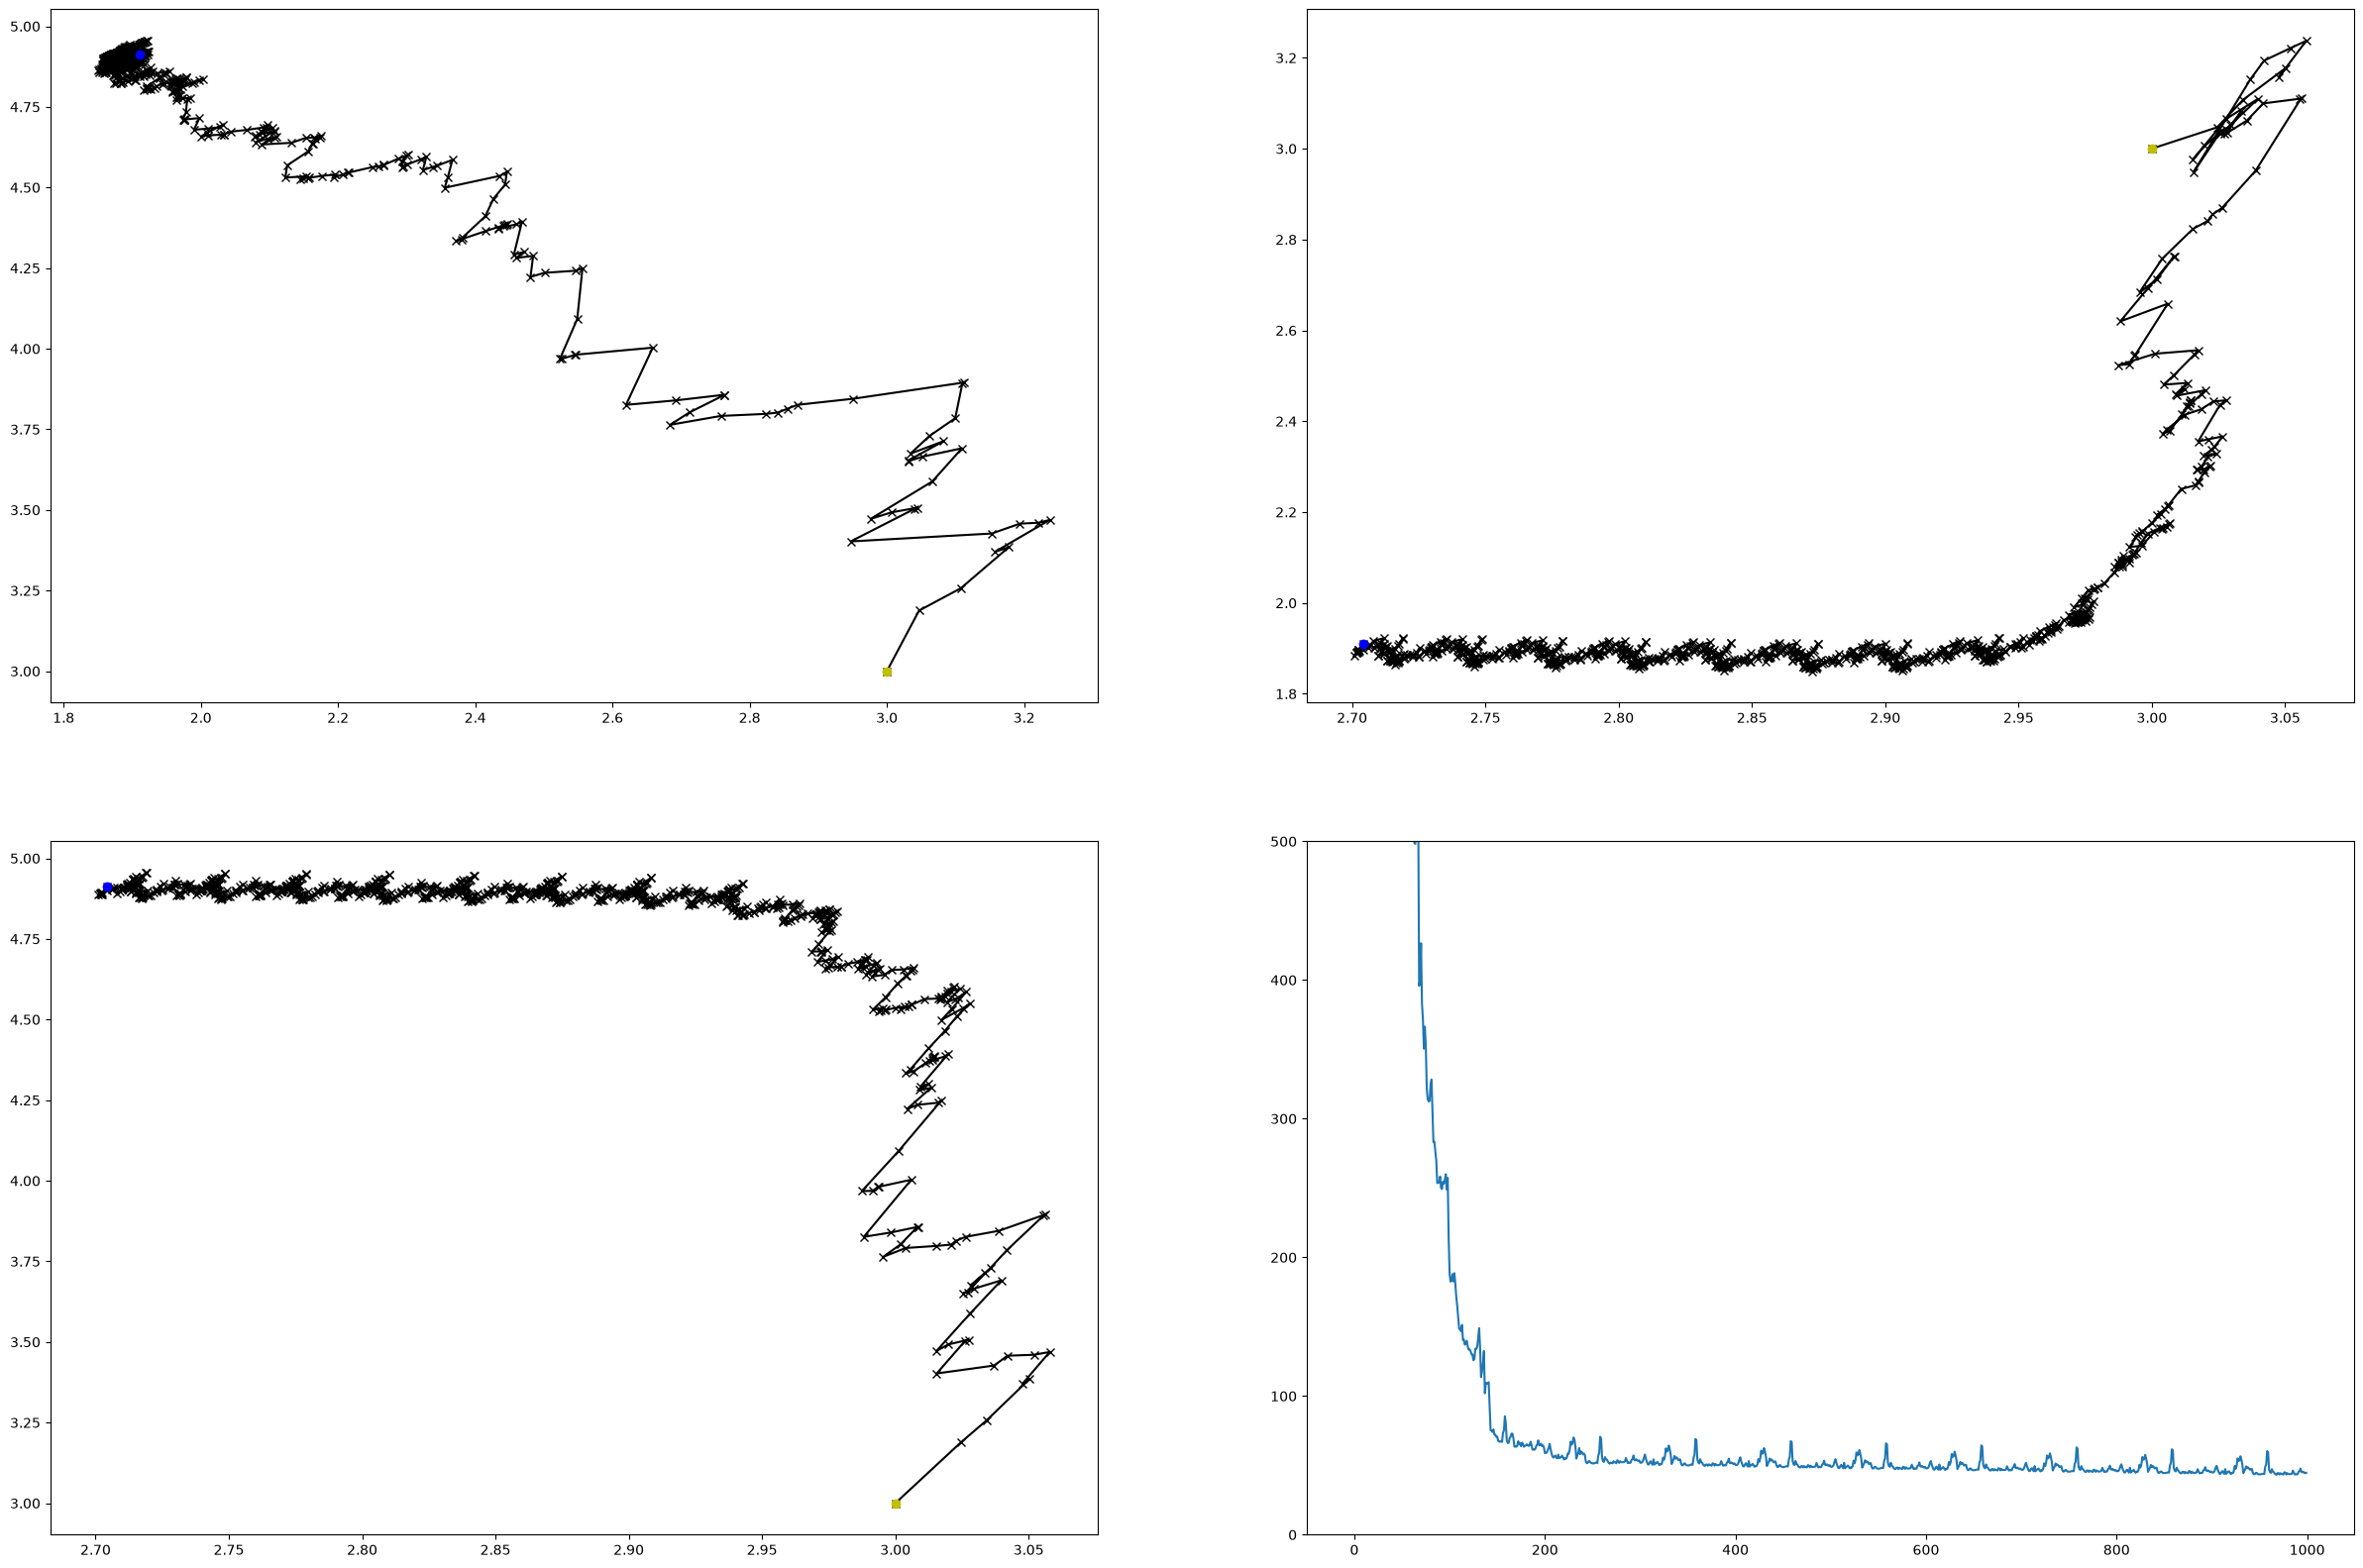

In [229]:
## Plotar os resultados - é um espaço de parâmetros 3d - plotamos fatias 2d
## Amarelo é ponto inicial e azul é ponto final
plt.figure(figsize = (30,20))
plt.subplot(2,2,1)
plt.plot(theta_path[:,1],theta_path[:,2],'k-x')
plt.plot(theta_path[0,1],theta_path[0,2],'yo')
plt.plot(theta_path[-1,1],theta_path[-1,2],'bo')
plt.subplot(2,2,2)
plt.plot(theta_path[:,0],theta_path[:,1],'k-x')
plt.plot(theta_path[0,0],theta_path[0,1],'yo')
plt.plot(theta_path[-1,0],theta_path[-1,1],'bo')

plt.subplot(2,2,3)
plt.plot(theta_path[:,0],theta_path[:,2],'k-x')
plt.plot(theta_path[0,0],theta_path[0,2],'yo')
plt.plot(theta_path[-1,0],theta_path[-1,2],'bo')

plt.subplot(2,2,4)
plt.plot(loss_vec)
plt.ylim([0,500])

(0.0, 500.0)

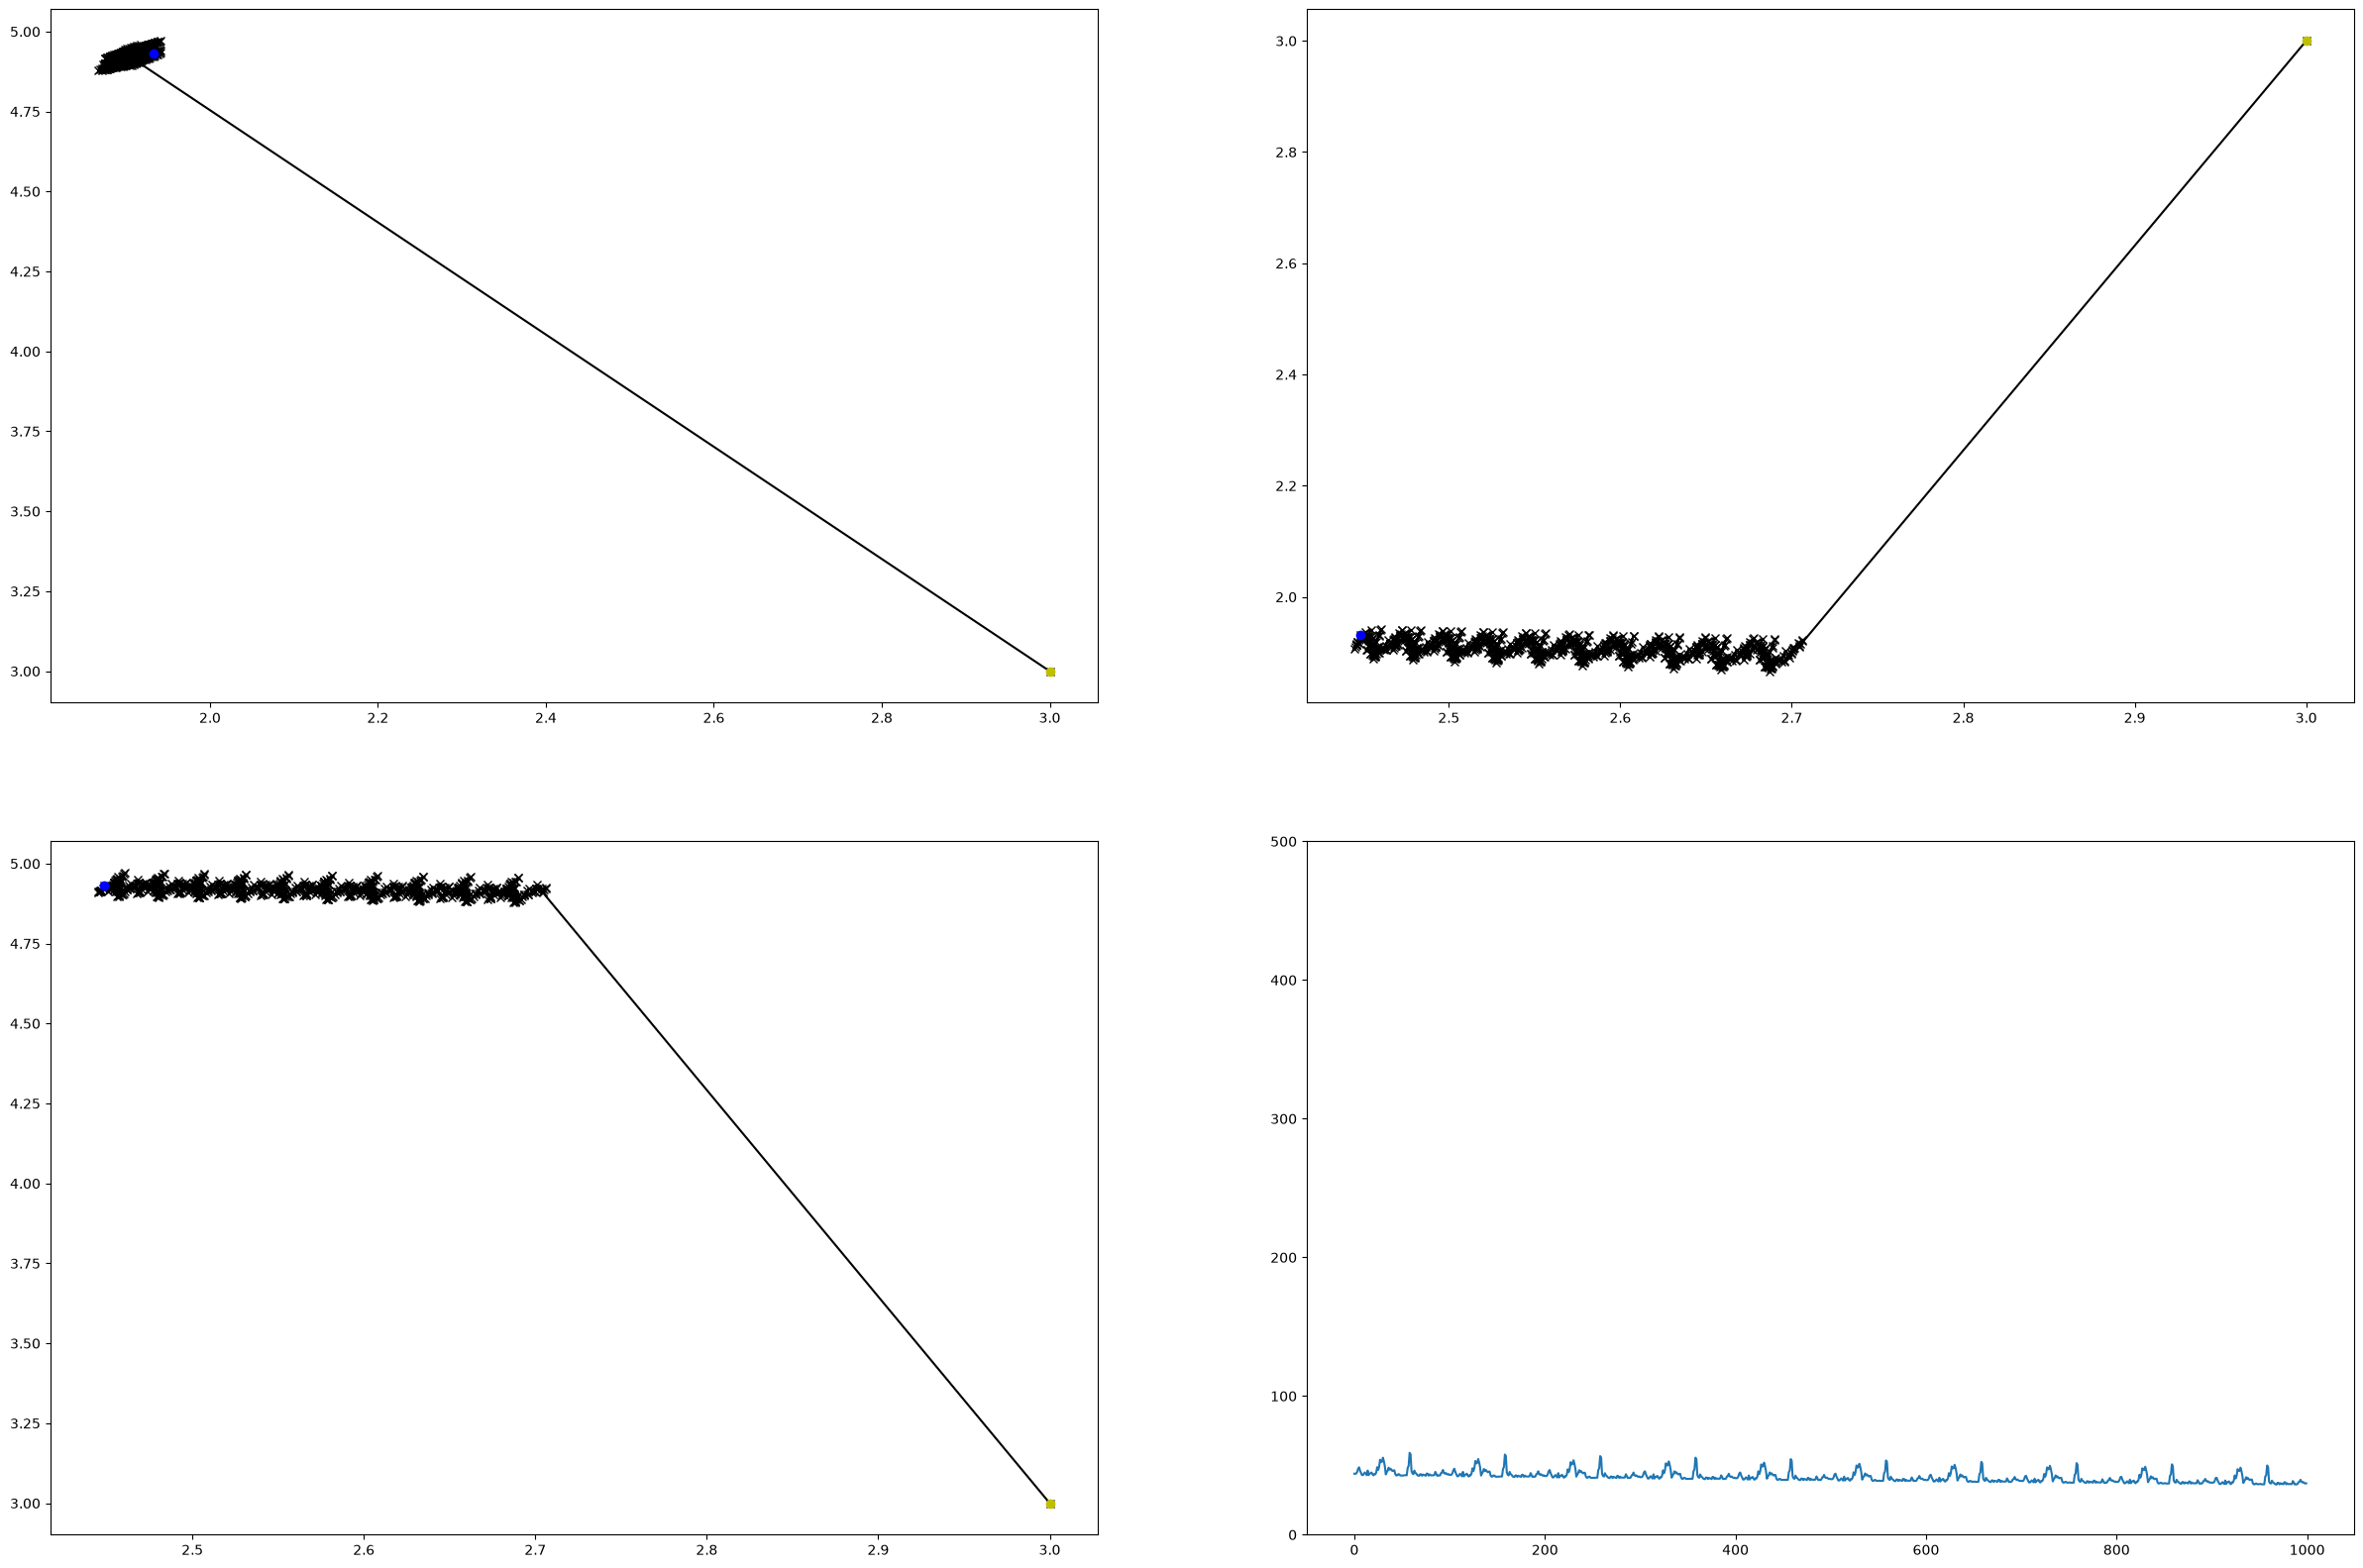

In [ ]:
## Agora é com você!

count = 0
for i in range(num_iter):

    indices = np.random.permutation(100)
    #embaralhar os indices

    x_mat_embaralhado = x_mat[indices]
    y_embaralhado = y[indices]
    #permutá-los igualmente

    for j in range(num_obs):
        count+=1
        y_pred = np.dot(theta.T,x_mat.T)
        loss_vec[count-1] = np.sum((y-y_pred)**2)
        grad_vec = (y[j]-y_pred[j])*(x_mat[j,:])
        theta = theta + learning_rate*grad_vec
        theta_path[count,:]=theta


plt.figure(figsize = (30,20))
plt.subplot(2,2,1)
plt.plot(theta_path[:,1],theta_path[:,2],'k-x')
plt.plot(theta_path[0,1],theta_path[0,2],'yo')
plt.plot(theta_path[-1,1],theta_path[-1,2],'bo')
plt.subplot(2,2,2)
plt.plot(theta_path[:,0],theta_path[:,1],'k-x')
plt.plot(theta_path[0,0],theta_path[0,1],'yo')
plt.plot(theta_path[-1,0],theta_path[-1,1],'bo')

plt.subplot(2,2,3)
plt.plot(theta_path[:,0],theta_path[:,2],'k-x')
plt.plot(theta_path[0,0],theta_path[0,2],'yo')
plt.plot(theta_path[-1,0],theta_path[-1,2],'bo')

plt.subplot(2,2,4)
plt.plot(loss_vec)
plt.ylim([0,500])

as tragetórias se comportram de forma bem mais "certeira", indo logo para o valor esperado e depois apenas "refinar". O gráfico erro (erro) já começa baixo, bem diferente do sem reorganizar os gráficos.